# 03 Análisis

**Resultado:** insights con cifra y el tamaño de la oportunidad

**Índice**

1. Cargar
2. Palanca 1: recorrido de compra
3. Palanca 2: clientes
4. Palanca 3: productos
5. Insights
6. Tamaño de la oportunidad

## 0. Librerías y rutas

In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
from dotenv import load_dotenv

# Opciones de vista
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Rutas del proyecto (el notebook vive en 03_notebooks)
RAIZ = Path.cwd().parent
ORIGINALES = RAIZ / '02_datos' / '01_Originales'
ANALITICO = RAIZ / '02_datos' / '02_Analitico'
RESULTADOS = RAIZ / '06_resultados'

# Variables de entorno (.env): ahí va DATABASE_URL
load_dotenv(RAIZ / '.env')

False

## 1. Cargar

Las tablas del notebook 02.

In [4]:
df = pd.read_pickle(ANALITICO / 'tablon_analitico.pkl')
df_grano_diario = pd.read_pickle(ANALITICO/'tablon_analitico_diario.pkl')

## 2. Palanca 1: Irradiacion

#### ¿Llega suficiente irradiación todos los días? [1]
#### ¿Es similar en ambas plantas? [2]
Se analiza la **Capatacion de luz solar** tomando un interverter por planta y analizando tramo - inverter -   en cada planta



In [ ]:
# Se toma dos inverter al azar para convertir el DF a nivel Planta-Tramo y analizar la captacion solar
# Se machaca inverter
captacion = (df.loc[(df['id_inversor']=='1BY6WEcLGh8j5v7') | (df['id_inversor']=='xMbIugepa2P7lBB'),
             'id_planta':'temperatura_modulo_c'])


In [14]:
# agregado por planta con condicion de irradiacion <> 0 (Noche) para las medias de irradiacion

def sin_sol(x):
    return x[x != 0].mean()

resultado_captacion = captacion.groupby('id_planta').agg({
    'irradiacion_wh_m2' :sin_sol, #media solo con valores !0
    'temperatura_ambiente_c' : 'mean',
    'temperatura_modulo_c' : 'mean'
}).round(2)



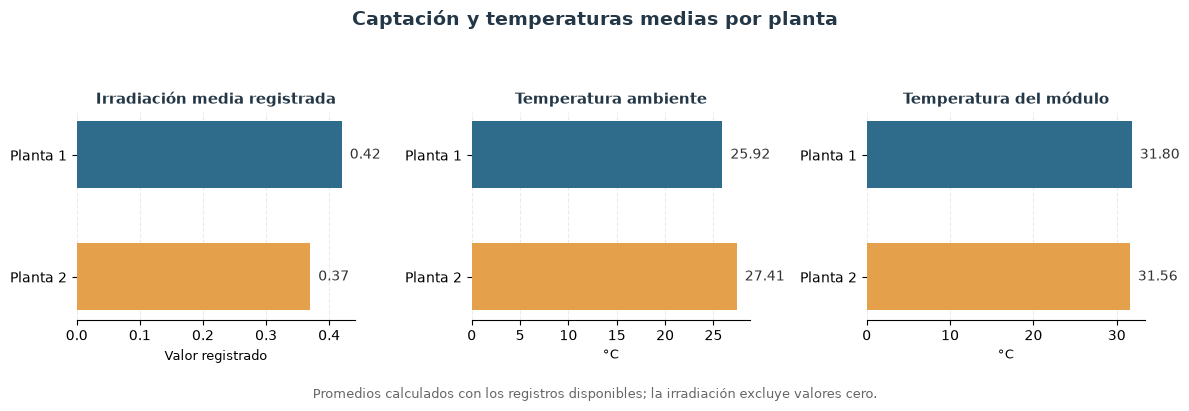

In [16]:
# ── Comparación de captación por planta ─────────

metricas = [
    ('irradiacion_wh_m2', 'Irradiación media registrada', 'Valor registrado'),
    ('temperatura_ambiente_c', 'Temperatura ambiente', '°C'),
    ('temperatura_modulo_c', 'Temperatura del módulo', '°C')
]

colores = {
    'Planta 1': '#2F6B8A',
    'Planta 2': '#E5A04B'
}

fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, metrica in zip(ejes, metricas):
    columna, titulo, unidad = metrica
    valores = resultado_captacion[columna]

    for posicion, planta in enumerate(valores.index):
        valor = valores.loc[planta]
        eje.barh(
            posicion,
            valor,
            color=colores.get(planta, '#777777'),
            height=0.55
        )
        eje.text(
            valor,
            posicion,
            f'  {valor:.2f}',
            va='center',
            fontsize=10,
            color='#333333'
        )

    eje.set_title(titulo, fontsize=11, weight='bold', color='#243746')
    eje.set_xlabel(unidad, fontsize=9)
    eje.set_yticks(range(len(valores.index)))
    eje.set_yticklabels(valores.index)
    eje.invert_yaxis()
    eje.spines['top'].set_visible(False)
    eje.spines['right'].set_visible(False)
    eje.spines['left'].set_visible(False)
    eje.grid(axis='x', linestyle='--', alpha=0.25)
    eje.set_axisbelow(True)

fig.suptitle(
    'Captación y temperaturas medias por planta',
    fontsize=14,
    weight='bold',
    color='#243746'
)
fig.text(
    0.5,
    0.01,
    'Promedios calculados con los registros disponibles; la irradiación excluye valores cero.',
    ha='center',
    fontsize=9,
    color='#666666'
)

plt.tight_layout(rect=[0, 0.06, 1, 0.90])
plt.show()

### Insight 5 

La irradiación media registrada es algo menor en Planta 2 (**0,37 frente a 0,42**), pero la temperatura media del módulo es prácticamente igual (**31,56 °C frente a 31,80 °C**). En este resumen no se observa una señal clara de problema de captación en Planta 2. Conviene comparar con las *fases de conversion e inversion* con la irradiacion antes de descartar una anomalía.

_____________________________________________________________

#### Distribucion por hora [3]


Sobre la irradiación:

¿Llega suficiente irradiación todos los días?
¿Es similar en ambas plantas?
¿Cómo es su distribución por hora?
¿Cómo se relaciona con la temperatura ambiente y la temperatura del módulo?
Sobre las plantas:

¿Les llega la misma cantidad de irradiación?
¿Tienen similar número de inverters?
¿Generan similar cantidad de DC?
¿Generan similar cantidad de AC?
Sobre la generación de DC:

¿Cuál es la relación entre irradiación y generación de DC?
¿Se ve afectada en algún momento por la temperatura ambiente o del módulo?
¿Es similar en ambas plantas?
¿Cómo se distribuye a lo largo del día?
¿Es constante a lo largo de los días?
¿Es constante en todos los inverters?
¿Ha habido momentos de fallos?
Sobre la generación de AC:

¿Cuál es la relación entre DC y generación de AC?
¿Es similar en ambas plantas?
¿Cómo se distribuye a lo largo del día?
¿Es constante a lo largo de los días?
¿Es constante en todos los inverters?
¿Ha habido momentos de fallos?
Sobre los medidores y sensores:

¿Son fiables los datos de irradiación?
¿Son fiables los datos de temperatura?
¿Son fiables los datos de DC?
¿Son fiables los datos de AC?
¿Son similares los datos entre ambas plantas?

## 3. Palanca 2: clientes

Igual: pregunta, cálculo, respuesta en una línea.

## 4. Palanca 3: productos

Igual.

## 5. Insights

Cada uno con cifra, específico y con una acción.

## 6. Tamaño de la oportunidad

Cuánta plata deja mover cada palanca, en tres escenarios.

In [ ]:
escenarios = pd.DataFrame({
    'escenario': ['conservador', 'medio', 'optimista'],
    'mejora': [0.02, 0.05, 0.10],
})
# escenarios['ingreso_extra'] = ingresos_actuales * escenarios['mejora']
escenarios

## Conclusión

En tres o cuatro líneas: qué se encontró, qué se decidió y qué pasa a la siguiente fase, con cifras.